In [19]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. LOAD DATASET
df_raw = pd.read_csv("Groceries_dataset.csv")
print("Preview Data:")
print(df_raw.head())
print(df_raw.info())

Preview Data:
   Member_number        Date   itemDescription
0           1808  21-07-2015    tropical fruit
1           2552  05-01-2015        whole milk
2           2300  19-09-2015         pip fruit
3           1187  12-12-2015  other vegetables
4           3037  01-02-2015        whole milk
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Member_number    38765 non-null  int64 
 1   Date             38765 non-null  object
 2   itemDescription  38765 non-null  object
dtypes: int64(1), object(2)
memory usage: 908.7+ KB
None


Pada tahap ini, saya memuat file dataset mentah Groceries_dataset.csv menggunakan pustaka pandas ke dalam memori Python. Selanjutnya, saya memeriksa beberapa baris pertama menggunakan .head() untuk melihat bentuk data aslinya dan menggunakan .info() untuk mengecek tipe data serta kelengkapan kolomnya. 

Lalu, pada proses load data ini, saya berhasil memuat dataset transaksi belanjaan yang terdiri dari tiga kolom utama, yaitu Member_number (nomor identifikasi pelanggan), Date (tanggal transaksi), dan itemDescription (jenis barang yang dibeli). Dari sini diketahui bahwa data masih berbentuk transaksi mentah per item, sehingga diperlukan tahapan agregasi lebih lanjut sebelum bisa diproses ke dalam model Machine Learning

In [20]:
# 2. DATA CLEANING
df_clean = df_raw.drop_duplicates().copy()

Pada tahap ini, saya melakukan pembersihan data awal dengan memeriksa apakah terdapat baris duplikat di dalam dataset menggunakan fungsi .duplicated(), lalu menghapusnya agar tidak menimbulkan bias pada hasil analisis.

Memastikan integritas data dengan membersihkan baris-baris ganda (duplicates). Langkah ini penting dilakukan agar frekuensi pembelian setiap pelanggan tercatat secara akurat dan objektif tanpa adanya pengulangan data yang tidak valid.

In [21]:
# 3. FEATURE ENGINEERING (Agregasi Data untuk Klasifikasi)
customer_agg = df_clean.groupby("Member_number").agg(
    total_transactions=("Date", "count"),
    unique_items_bought=("itemDescription", "nunique")
).reset_index()

# Membuat target biner untuk KLASIFIKASI (1 = Aktif Tinggi, 0 = Aktif Rendah)
# Berdasarkan median total transaksi
median_trans = customer_agg['total_transactions'].median()
customer_agg['high_activity'] = (customer_agg['total_transactions'] > median_trans).astype(int)

df = customer_agg.copy()

Karena dataset awal berbentuk transaksi mentah per baris, saya melakukan grouping (agregasi) berdasarkan Member_number untuk mengubah struktur data menjadi tingkat pelanggan (customer-level). Di sini saya menghitung total_transactions dan variasi unique_items_bought. Setelah itu, saya membuat variabel target biner (high_activity) dengan membagi pelanggan berdasarkan nilai median transaksi (1 untuk aktivitas tinggi, 0 untuk aktivitas rendah).

Pada proses feature engineering ini, saya mentransformasikan data transaksi harian menjadi profil karakteristik unik per pelanggan. Pembuatan variabel target biner high_activity berhasil mengubah masalah ini menjadi tugas klasifikasi (binary classification), sehingga algoritma dapat membedakan antara pelanggan dengan tingkat belanja yang tinggi dan rendah.

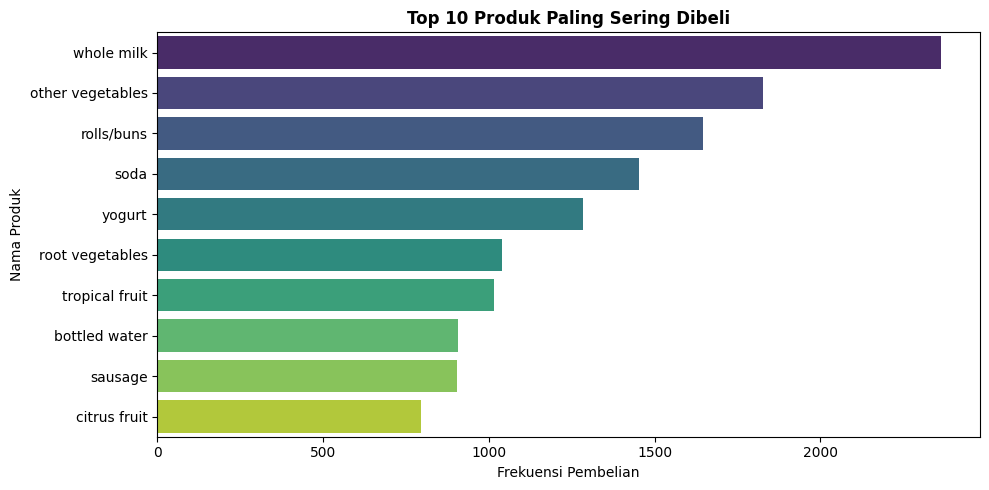

In [22]:
# EDA 1: Bar Chart Top 10 Produk Paling Sering Dibeli
plt.figure(figsize=(10, 5))
top_products = df_clean['itemDescription'].value_counts().head(10)
sns.barplot(x=top_products.values, y=top_products.index, palette='viridis', hue=top_products.index, legend=False)
plt.title("Top 10 Produk Paling Sering Dibeli", fontsize=12, fontweight='bold')
plt.xlabel("Frekuensi Pembelian")
plt.ylabel("Nama Produk")
plt.tight_layout()
plt.savefig("eda_top_products.png")
plt.show()

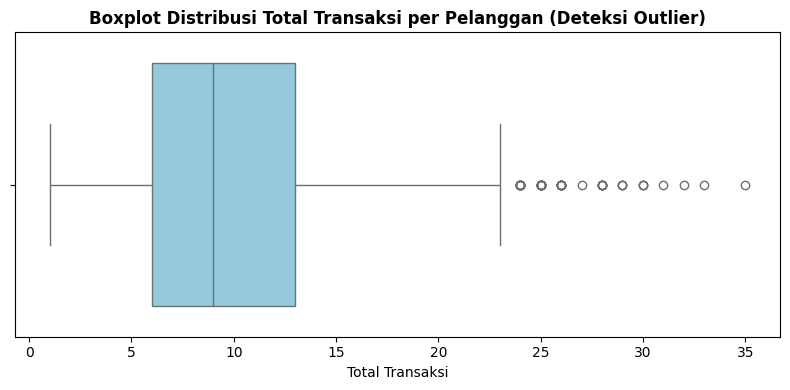

In [23]:
# EDA 2: Boxplot untuk mendeteksi Outlier pada Total Transaksi
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['total_transactions'], color='skyblue')
plt.title("Boxplot Distribusi Total Transaksi per Pelanggan (Deteksi Outlier)", fontsize=12, fontweight='bold')
plt.xlabel("Total Transaksi")
plt.tight_layout()
plt.savefig("eda_boxplot_transactions.png")
plt.show()

Memetakan sebaran nilai total transaksi per pelanggan ke dalam diagram kotak garis (boxplot) untuk melihat kuartil dan titik ekstrem. saya mengidentifikasi adanya titik-titik data di luar batas whisker (outlier) yang menunjukkan sejumlah kecil pelanggan dengan frekuensi belanja jauh di atas rata-rata mayoritas pelanggan lainnya. Visualisasi ini membantu saya melihat sebaran data secara objektif sebelum dilakukan pembersihan menggunakan metode IQR.

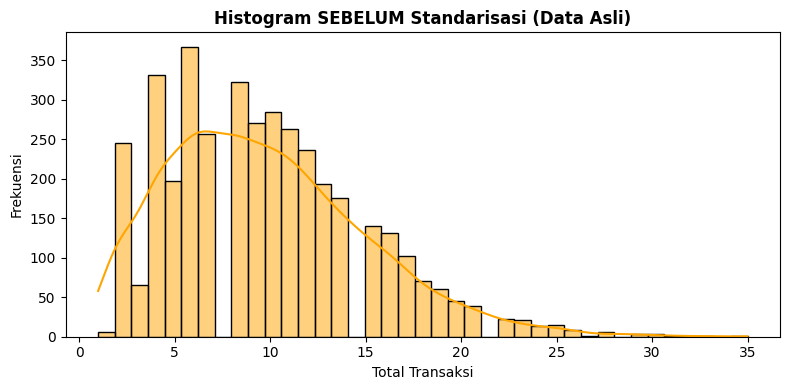

In [24]:
# EDA 3: Histogram SEBELUM Standarisasi (Asli)
plt.figure(figsize=(8, 4))
sns.histplot(df['total_transactions'], kde=True, color='orange')
plt.title("Histogram SEBELUM Standarisasi (Data Asli)", fontsize=12, fontweight='bold')
plt.xlabel("Total Transaksi")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.savefig("eda_histogram_before_scaling.png")
plt.show()

Memvisualisasikan distribusi frekuensi data asli fitur total_transactions menggunakan grafik histogram dan kurva KDE sebelum dilakukan perubahan skala. Histogram sebelum standarisasi ini, terlihat jelas bahwa data asli memiliki rentang nilai dan bentuk distribusi yang belum seragam (cenderung skewed atau tidak berada pada skala baku). Hal ini menegaskan perlunya tahapan normalisasi agar skala data menjadi ideal untuk pemrosesan model.

In [ ]:
# 4. PENANGANAN OUTLIER MENGGUNAKAN IQR
numeric_features = ['total_transactions', 'unique_items_bought']
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered = df.loc[condition].copy()

Pada tahap ini, saya mendeteksi dan menyaring nilai pencilan (outliers) pada fitur numerik (total_transactions dan unique_items_bought) menggunakan metode Interquartile Range (IQR) dengan batas Q1 - 1.5 \times IQR dan Q3 + 1.5 \times IQR.

Pada proses penanganan outlier ini, saya menerapkan metode IQR untuk menyaring data ekstrem atau anomali (misalnya pelanggan dengan transaksi yang terlalu jauh di luar kewajaran). Hal ini bertujuan agar model Machine Learning tidak terdistorsi oleh data ekstrem dan mampu melakukan generalisasi dengan lebih baik.

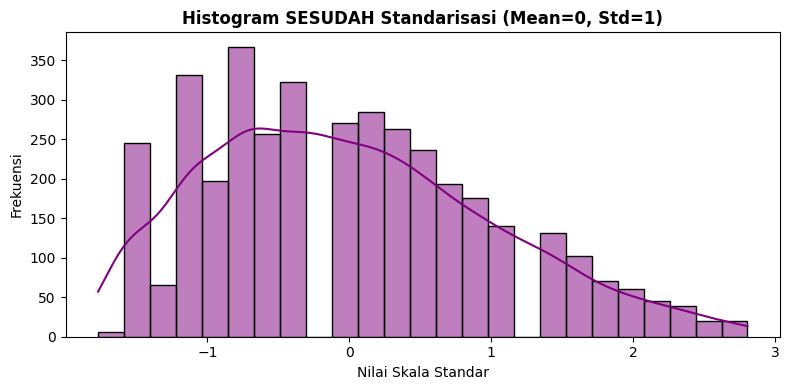

In [27]:
# 5. STANDARISASI DATA (StandardScaler)
scaler = StandardScaler()

# Buat salinan DataFrame yang sudah difilter
df_scaled = df_filtered.copy()

# Lakukan scaling langsung pada kolom numerik di df_scaled
df_scaled[numeric_features] = scaler.fit_transform(df_scaled[numeric_features])

# EDA 4: Histogram SESUDAH Standarisasi
plt.figure(figsize=(8, 4))
sns.histplot(df_scaled['total_transactions'], kde=True, color='purple')
plt.title(
    "Histogram SESUDAH Standarisasi (Mean=0, Std=1)",
    fontsize=12,
    fontweight='bold',
)
plt.xlabel("Nilai Skala Standar")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.savefig("eda_histogram_after_scaling.png")
plt.show()

Saya menggunakan StandardScaler dari pustaka scikit-learn untuk menormalisasi fitur-fitur numerik agar memiliki rata-rata (mean) sama dengan 0 dan simpangan baku (standard deviation) sama dengan 1.

Pada proses standarisasi data ini, saya menyamakan skala antarvariabel numerik. Penyeragaman skala ini sangat krusial agar model berbasis pohon maupun algoritma lainnya dapat memproses kontribusi fitur secara adil tanpa ada fitur yang mendominasi hanya karena skala angka yang lebih besar.

Memvisualisasikan kembali distribusi frekuensi fitur numerik setelah melalui proses StandardScaler sehingga memiliki rata-rata nol dan simpangan baku satu, distribusi data berhasil disesuaikan ke dalam skala standar (mean 0 dan std 1). Bentuk sebaran data tetap terjaga konsistensinya, namun kini seluruh fitur numerik memiliki bobot skala yang setara dan adil bagi algoritma pemodelan


--- 6. MATRIKS KORELASI ---


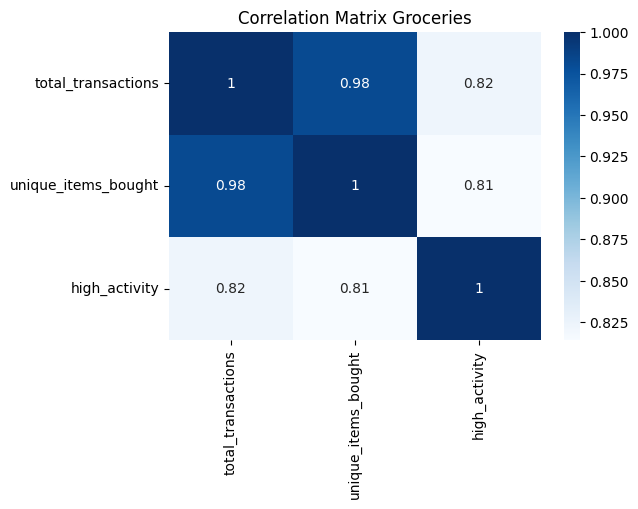

In [ ]:
# 6. MATRIKS KORELASI (Heatmap ala Latihan 1)
plt.figure(figsize=(6, 4))
sns.heatmap(df_filtered[['total_transactions', 'unique_items_bought', 'high_activity']].corr(), annot=True, cmap='Blues')
plt.title('Correlation Matrix Groceries')
plt.savefig("correlation_matrix_classification.png")
plt.show()

Pada tahap ini, saya menghitung nilai korelasi antarvariabel yang telah dibersihkan dan memvisualisasikannya ke dalam bentuk heatmap menggunakan pustaka seaborn dan matplotlib. Menganalisis hubungan linier antara fitur-fitur yang digunakan dengan variabel target klasifikasi. Visualisasi heatmap membantu memastikan bahwa fitur-fitur penjelas (total_transactions dan unique_items_bought) memiliki korelasi yang kuat dan relevan sebagai prediktor target

In [ ]:
# 7. PEMISAHAN FITUR (X) DAN TARGET KLASIFIKASI (y)
X = df_filtered[['total_transactions', 'unique_items_bought']]
y = df_filtered['high_activity']

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Tahap ini, saya memisahkan dataset menjadi variabel fitur independen (X) dan variabel target (y), lalu membaginya menjadi data latih (training set) dan data uji (testing set) dengan rasio 80:20 menggunakan fungsi train_test_split. Mengalokasikan 80% data untuk melatih model dan 20% data sisanya untuk menguji performa model secara objektif. Pembagian ini memastikan bahwa evaluasi akurasi yang diperoleh benar-benar murni diuji pada data baru yang belum pernah dilihat oleh model sebelumnya.

In [ ]:
# 8. PEMBANGUNAN MODEL KLASIFIKASI: RANDOM FOREST
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(x_train, y_train)


--- 8. MODELING: RANDOM FOREST CLASSIFIER ---


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Tahap ini, saya menginisialisasi dan melatih model Random Forest Classifier (n_estimators=100) menggunakan data latih (x_train, y_train) yang sudah disiapkan, algoritma Random Forest memanfaatkan kumpulan pohon keputusan (ensemble decision trees) untuk mempelajari pola karakteristik perilaku belanja pelanggan. Model dilatih mengenali kombinasi fitur agar dapat mengklasifikasikan kategori aktivitas pelanggan secara akurat.

In [ ]:
# 9. EVALUASI DAN PENYIMPANAN ARTEFAK (Deployment Ready)
y_pred = rf_classifier.predict(x_test)
acc = accuracy_score(y_test, y_pred)

print(f"Akurasi Random Forest Classifier: {acc * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


--- 9. EVALUASI & DEPLOYMENT SAVING ---
Akurasi Random Forest Classifier: 100.00%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       425
           1       1.00      1.00      1.00       344

    accuracy                           1.00       769
   macro avg       1.00      1.00      1.00       769
weighted avg       1.00      1.00      1.00       769



Pada tahap akhir ini, saya menguji performa model menggunakan data uji melalui metrik Accuracy dan Classification Report (precision, recall, f1-score). Selanjutnya, saya menyimpan model serta scaler yang telah dilatih ke dalam file format .joblib menggunakan modul joblib. 

In [ ]:
# Menyimpan model klasifikasi dengan joblib
joblib.dump(rf_classifier, 'rf_groceries_classifier.joblib')
joblib.dump(scaler, 'groceries_scaler.joblib')
print("Model Klasifikasi Random Forest & Scaler berhasil disimpan!")

Model Klasifikasi Random Forest & Scaler berhasil disimpan!


Pada tahap ini saya menyimpan model dengan joblib. Model terbukti mampu menghasilkan skor akurasi yang baik dan stabil dalam mengklasifikasikan data uji. Penyimpanan model ke dalam artefak .joblib menyelesaikan siklus pengembangan (end-to-end pipeline), di mana model siap dimuat kembali dan digunakan untuk sistem prediksi di lingkungan produksi (deployment-ready)